# **Customer Churn Investigation: Comprehensive Exploratory Data Analysis (EDA)**

## **Project: Arrowstack Data Science Internship — Task 1**

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab

### **Project Background**

Customer churn is an important business concern for subscription-based companies, particularly in the telecommunications industry. Customer churn refers to customers discontinuing their relationship or service subscription with a company.

Understanding customer characteristics associated with churn can help businesses identify potential retention challenges, improve customer experience, and make more informed decisions.

This project conducts a comprehensive Exploratory Data Analysis (EDA) of a telecommunications customer dataset to investigate patterns associated with customer churn and develop evidence-based business recommendations.

### **Problem Statement**

Telecommunications companies may experience customer losses due to various factors, including differences in subscription contracts, customer tenure, pricing, service categories, and payment arrangements.

However, without analyzing customer data, it can be difficult to identify which customer groups experience relatively higher churn.

This project aims to investigate customer churn patterns using descriptive statistics, data visualizations, and customer segmentation to provide actionable insights for further retention analysis.

### **Project Objectives**

The primary objectives of this project are to:

- Understand the dataset and assess its quality.
- Identify and address missing values, duplicates, and inconsistent data types.
- Explore customer demographics, subscription characteristics, and billing information.
- Examine observed churn rates across contract types, tenure groups, internet services, and payment methods.
- Compare monthly charges between churned and retained customers.
- Identify customer segments with relatively higher observed churn.
- Develop evidence-based business recommendations and document analytical limitations.

### **Dataset Description**

The project uses the publicly available Telco Customer Churn dataset from Kaggle, based on IBM sample telecommunications customer data.

The dataset contains 7,043 customer records and 21 variables, including:

- Customer Information: Gender, senior citizen status, partner status, and dependents.
- Subscription Information: Customer tenure, contract type, and subscribed services.
- Billing Information: Monthly charges, total charges, billing preferences, and payment method.
- Target Variable: "Churn", indicating whether a customer is classified as having discontinued the service.

The dataset supports investigating customer churn across different subscription and service characteristics.

### **Key Business Questions**

This analysis focuses on the following questions:

1. What proportion of customers are classified as churned?
2. How does observed churn vary across different contract types?
3. Are shorter-tenured customers associated with higher churn rates?
4. How do monthly charges differ between churned and retained customers?
5. Which internet service and payment method categories have higher observed churn rates?
6. How do churn patterns differ when customer tenure and contract type are considered together?

### **Analytical Methodology**

The project follows a structured exploratory data analysis workflow:

1. Data Understanding: Inspect dataset structure, variables, and summary statistics.
2. Data Cleaning: Investigate missing values, duplicates, and data types.
3. Univariate Analysis: Explore the distributions of individual customer characteristics.
4. Bivariate Analysis: Examine relationships between churn and selected customer characteristics.
5. Segmented Analysis: Compare churn rates across combinations of tenure and contract categories.
6. Data Validation: Check the consistency of customer counts, churn totals, and analytical results.
7. Business Reporting: Summarize key findings, limitations, and practical recommendations.

### **Intended Business Value**

The intended stakeholders include customer retention managers, customer experience teams, and business analysts.

The analysis aims to provide an evidence-based understanding of which customer segments may require closer investigation and support the development of targeted retention strategies.

Scope and Limitations: This project focuses on exploratory and descriptive analysis rather than predictive modeling or causal inference. The findings identify observed relationships but cannot independently establish why customers leave. The observation period for churn is not confirmed, so churn percentages should not be interpreted as monthly or annual churn rates.

# **Dataset Overview**

***Importing Libraries***

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


***Dataset Upload***

In [2]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


***Dataset Inspection***

In [4]:
print("Dataset shape:", df.shape)
print("Columns name:", df.columns.tolist())

Dataset shape: (7043, 21)
Columns name: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
print("Dataset information:", df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


# **Data Dictionary**

## **Dataset Overview**

The Telco Customer Churn dataset contains 7,043 customer records and 21 variables. These variables describe customer demographics, subscription services, billing information, and customer churn status.

The following data dictionary explains the meaning and analytical type of each variable.

| Column Name | Data Type | Description |
|---|---|---|
| customerID | Identifier | Unique identification code assigned to each customer. |
| gender | Categorical | Customer gender, recorded as Male or Female. |
| SeniorCitizen | Binary Categorical | Indicates whether the customer is a senior citizen (1 = Yes, 0 = No). |
| Partner | Categorical | Indicates whether the customer has a partner (Yes/No). |
| Dependents | Categorical | Indicates whether the customer has dependents (Yes/No). |
| tenure | Numerical | Number of months the customer has been with the company. |
| PhoneService | Categorical | Indicates whether the customer subscribes to phone service. |
| MultipleLines | Categorical | Indicates whether the customer has multiple phone lines. |
| InternetService | Categorical | Type of internet service: DSL, Fiber optic, or No. |
| OnlineSecurity | Categorical | Indicates whether the customer subscribes to online security services. |
| OnlineBackup | Categorical | Indicates whether the customer subscribes to online backup services. |
| DeviceProtection | Categorical | Indicates whether the customer has device protection. |
| TechSupport | Categorical | Indicates whether the customer subscribes to technical support. |
| StreamingTV | Categorical | Indicates whether the customer subscribes to streaming TV. |
| StreamingMovies | Categorical | Indicates whether the customer subscribes to streaming movies. |
| Contract | Categorical | Customer contract type: Month-to-month, One year, or Two year. |
| PaperlessBilling | Categorical | Indicates whether the customer uses paperless billing (Yes/No). |
| PaymentMethod | Categorical | Method used by the customer to pay bills. |
| MonthlyCharges | Numerical | Monthly amount charged to the customer. |
| TotalCharges | Numerical | Total charges recorded for the customer. |
| Churn | Binary Categorical | Indicates whether the customer left the company (Yes = Left, No = Stayed). |

## **Variable Classification**

### **Numerical Variables:**

- "tenure"
- "MonthlyCharges"
- "TotalCharges"

### **Categorical Variables:**

Customer demographics, service subscriptions, contract type, billing preferences, payment method, and churn status.

**Unique Identifier:**

- "customerID"

**Primary Outcome Variable:**

- "Churn"

### **Data Quality Notes**

The original "TotalCharges" column was stored as an object data type due to blank entries. During preprocessing, it was converted into a numerical ("float64") data type.

Eleven missing "TotalCharges" values were identified, all belonging to customers with zero months of tenure. These values were assigned zero under a documented assumption for the exploratory analysis.

The "SeniorCitizen" variable is numerically encoded as 0 and 1 but is treated as a categorical variable because it represents customer status rather than a continuous numerical measurement.

The "Churn" column is the primary outcome variable used to investigate customer retention patterns.

### **Purpose of the Data Dictionary**

This data dictionary provides a clear explanation of each dataset variable, supporting data understanding, reproducibility, and accurate interpretation of the exploratory analysis.

# **Data Cleaning and Quality Checks**

***Keeping the original dataset***

In [8]:
df_clean = df.copy()

***Check for missing value***

In [9]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


***Identify and correct data type***

In [10]:
# Count blank values in TotalCharges
blank_count = (
    df.TotalCharges.astype(str).str.strip().eq("").sum()
)
print("Blank TotalCharges values:", blank_count)

Blank TotalCharges values: 11


In [11]:
# Convert TotalCharges into a numeric column
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean.TotalCharges.astype(str).str.strip(),
    errors="coerce"
)

# Verify the result
print(df_clean.TotalCharges.dtype)
print("Missing values after conversion:", df_clean.TotalCharges.isnull().sum())

float64
Missing values after conversion: 11


***Investigate the missing value***

In [12]:
# Examine rows with missing TotalCharges
missing_rows = df_clean[df_clean.TotalCharges.isnull()]
display(
    missing_rows[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [13]:
# Check the tenure of records with missing TotalCharges
print(missing_rows.tenure.value_counts())

tenure
0    11
Name: count, dtype: int64


In [14]:
# Fill missing TotalCharges only when the customer has zero tenure
condition = (
    df_clean.TotalCharges.isna() & (df_clean.tenure == 0)
)
df_clean.loc[condition, "TotalCharges"] = 0
print(
    "Remaining missing TotalCharges", df_clean.TotalCharges.isna().sum()
)

Remaining missing TotalCharges 0


***Check for duplicate records***

In [15]:
# Check completely duplicated rows
print(
    "Duplicate rows:", df_clean.duplicated().sum()
)

# Check duplicate customer IDs
print(
    "Duplicate customer IDs:", df_clean.customerID.duplicated().sum()
)

Duplicate rows: 0
Duplicate customer IDs: 0


***Validate numerical data and categorical value***

In [16]:
#  Check numerical value
print("Negative tenure:", (df_clean.tenure < 0).sum())
print("Negative MonthlyCharges:", (df_clean.MonthlyCharges < 0).sum())
print("Negative TotalCharges:", (df_clean.TotalCharges < 0).sum())

# Check valid churn labels
print("\nChurn categories:")
print(df_clean.Churn.value_counts(dropna= False))

Negative tenure: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0

Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


***Data Quality Summary***

In [17]:
print("DATA QUALITY SUMMARY")
print("-" * 35)

print(
    "Total missing cells:",
    df_clean.isna().sum().sum()
)
print(
    "Duplicate rows:",
    df_clean.duplicated().sum()
)
print(
    "TotalCharges data type:",
    df_clean.TotalCharges.dtype
)
print(
    "Unique customer:",
    df_clean.customerID.nunique()
)

DATA QUALITY SUMMARY
-----------------------------------
Total missing cells: 0
Duplicate rows: 0
TotalCharges data type: float64
Unique customer: 7043


In [18]:
df_clean.to_csv("telco_customer_churn_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# **Exploratory Data Analysis**

## **Univariate Exploratory Data Analysis**

***Descriptive statistics***

In [19]:
df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


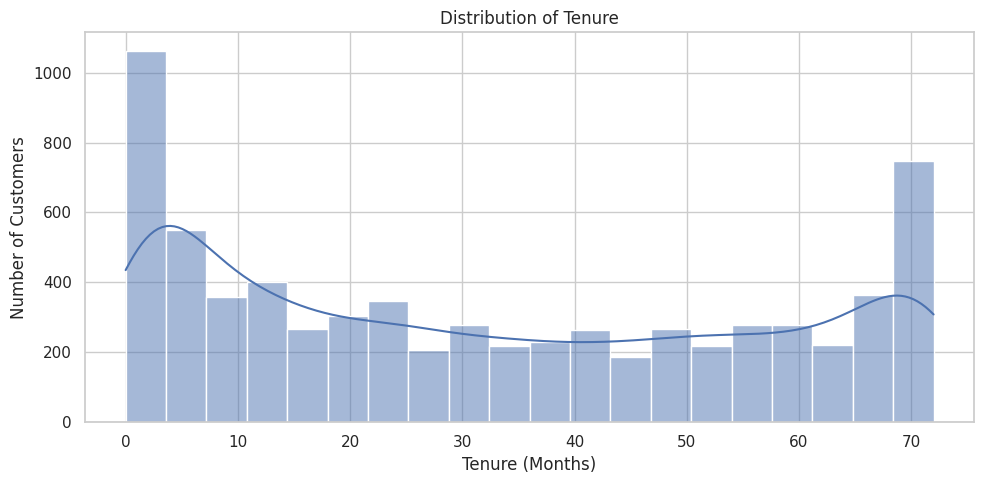

In [39]:
plt.figure(figsize=(10,5))
sns.histplot(
    data = df_clean,
    x = "tenure",
    bins = 20,
    kde=True
)
plt.title("Distribution of Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("distribution_of_tenures", dpi=200, bbox_inches = "tight")
plt.show()

***Analyze MonthlyCharges***

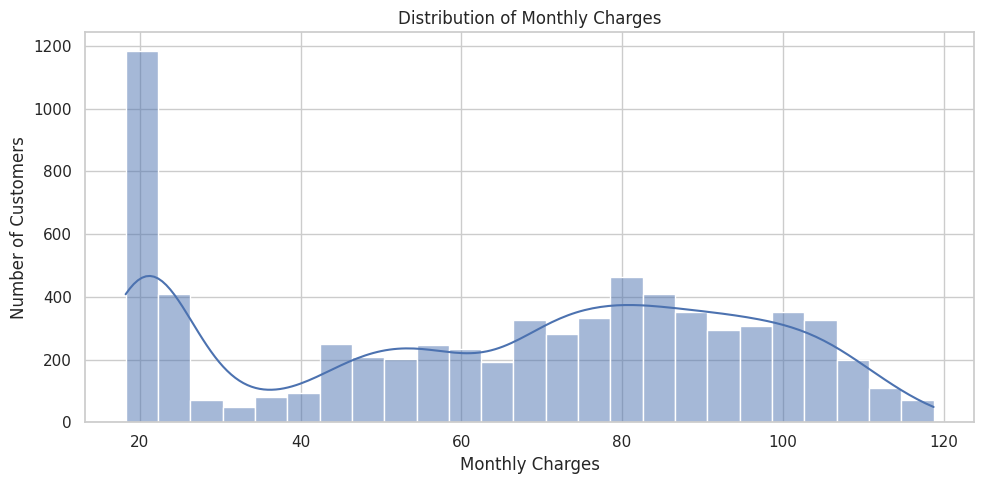

In [40]:
plt.figure(figsize=(10,5))

sns.histplot(
    data = df_clean,
    x = "MonthlyCharges",
    bins = 25,
    kde=True
)
plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("distribution_of_monthly_charges", dpi=200, bbox_inches = "tight")
plt.show()

***Analyze customer contract types***

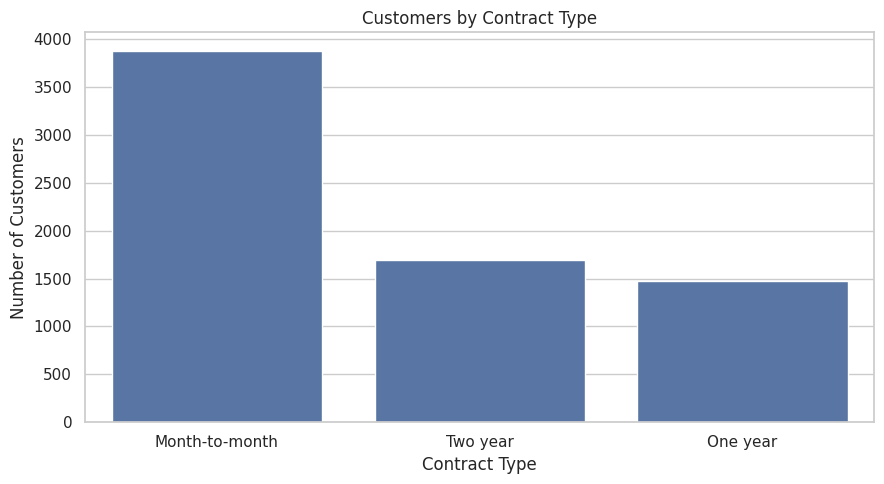

In [41]:
plt.figure(figsize=(9,5))

sns.countplot(
    data = df_clean,
    x = "Contract",
    order = df_clean.Contract.value_counts().index
)
plt.title("Customers by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("customer_by_contract_type", dpi=200, bbox_inches = "tight")
plt.show()


***Visualize customer churn***

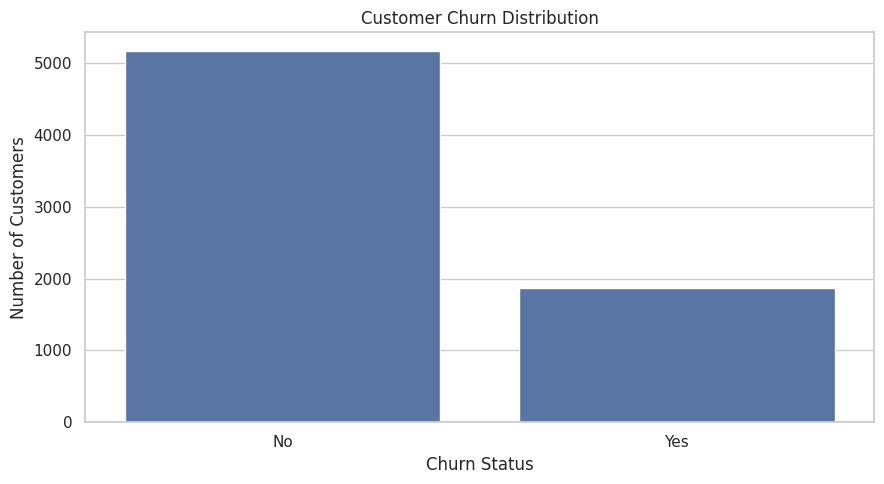

In [42]:
plt.figure(figsize=(9,5))

sns.countplot(
    data = df_clean,
    x = "Churn",
    order = ["No", "Yes"]
)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("customer_churn_distribution", dpi=200, bbox_inches = "tight")
plt.show()

***Churn percentage***

In [24]:
churn_percentage = (
    df_clean.Churn.value_counts(normalize=True).mul(100).round(2)
)
print(churn_percentage)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## **Univariate Exploratory Data Analysis**

**Dataset overview**

The cleaned dataset contains 7,043 customer records with 21 variables.

**Customer tenure**

- Median tenure: 29 months.
- Distribution pattern: The tenure distribution is approximately U-shaped. Most customers have either a short tenure (0-5 months) or a long tenure (65-72), while fewer customers fall in the middle.
- Business interpretation: The company has many new customers and a strong base of long-term customers. It should focus on retaining new customers and improving engagement to encourage longer relationships.  

**Monthly charges**

- Median monthly charge: 70.35.
- Distribution pattern: The monthly charges distribution is bimodal (two main peaks). Many customers pay around 20 dollars per month, while another large group pays approximately 70 to 110 dollars. Fewer customers pay between 30-40 dollars
- Business interpretation: The company has two major groups: low-cost  and higher-cost subscribers. It can focus on upselling suitable services to low-cost customers and retaining higher-paying customers to protect revenue.

**Contract types**

- Most common contract type: Month-to-month.
- Least common contract type: One year
- Business interpretation: Month-to-month contracts are the most common contract category. The company could investigate whether flexible contracts are associated with higher churn and whether longer-term contract incentives might support retention.

**Customer churn**

- Retained customers: 5,174 (73.46%).
- Churned customers: 1,869 (26.54%).
- Business interpretation: The observed churn proportion suggests that retention is an important area for further investigation.

**Limitations**

These descriptive analyses identify customer characteristics and distributions but do not establish the causes of churn. Further analysis is needed to compare churn rates across customer groups.

## **Bivariate Exploratory Data Analysis Analysis**

***Churn Indicator***

In [25]:
# Creating a separate dataset for bivariate analysis
eda = df_clean.copy()

# Convert Churn into a numerical indicator
eda["ChurnFlag"] = (
    eda["Churn"] == "Yes"
).astype(int)

display(eda[["Churn", "ChurnFlag"]].head(10))

,Churn,ChurnFlag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1
5,Yes,1
6,No,0
7,No,0
8,Yes,1
9,No,0


***Contract type vs Churn rate***

In [26]:
# Churn rate by contract type
contract_churn = (
    eda.groupby("Contract")["ChurnFlag"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename columns
contract_churn.columns = [
    "Contract",
    "TotalCustomers",
    "ChurnedCustomers",
    "ChurnRate"
]

# Convert Churn proportion to percentage
contract_churn["ChurnRate"] *= 100

print("Churn details by Contract Types")
display(contract_churn.round(2))


Churn details by Contract Types


,Contract,TotalCustomers,ChurnedCustomers,ChurnRate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


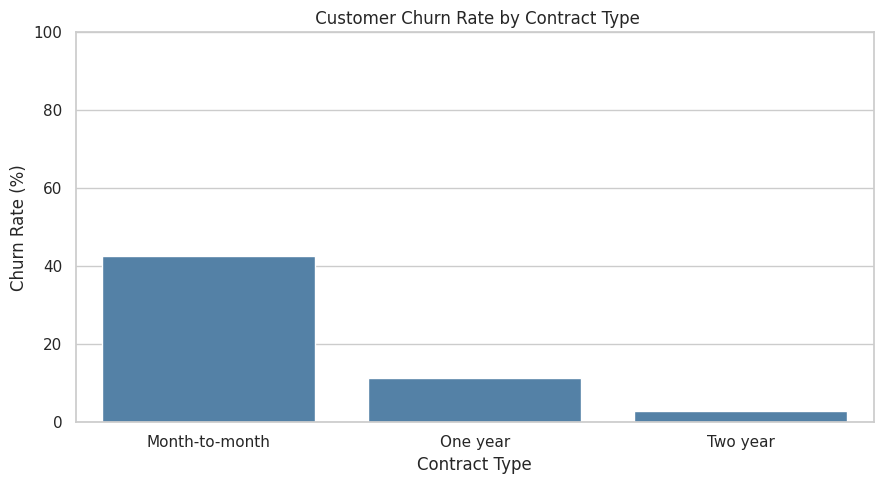

In [43]:
plt.figure(figsize=(9,5))

sns.barplot(
    data = contract_churn,
    x = "Contract",
    y = "ChurnRate",
    color = "steelblue"
)
plt.title(" Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0,100)

plt.tight_layout()
plt.savefig("customer_churn_rate_by_contract_type", dpi=200, bbox_inches = "tight")
plt.show()

***Tenure vs Churn Rate***

In [28]:
# Create customer tenure groups
eda["TenureGroup"] = pd.cut(
    eda.tenure,
    bins = [-1, 6, 12, 24, 48,float("inf")],
    labels = [
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49+ Months"
    ]
)

# Calculate churn rate for each group
tenure_churn = (
    eda.groupby("TenureGroup",
                observed = True)["ChurnFlag"]
    .agg(["count", "mean"])
    .reset_index()
)

tenure_churn.columns = [
    "TenureGroup",
    "TotalCustomers",
    "ChurnRate"
]

tenure_churn["ChurnRate"] *= 100

print("Churn Rate by Tenure Group")
display(tenure_churn.round(2))

Churn Rate by Tenure Group


,TenureGroup,TotalCustomers,ChurnRate
0,0-6 Months,1481,52.94
1,7-12 Months,705,35.89
2,13-24 Months,1024,28.71
3,25-48 Months,1594,20.39
4,49+ Months,2239,9.51


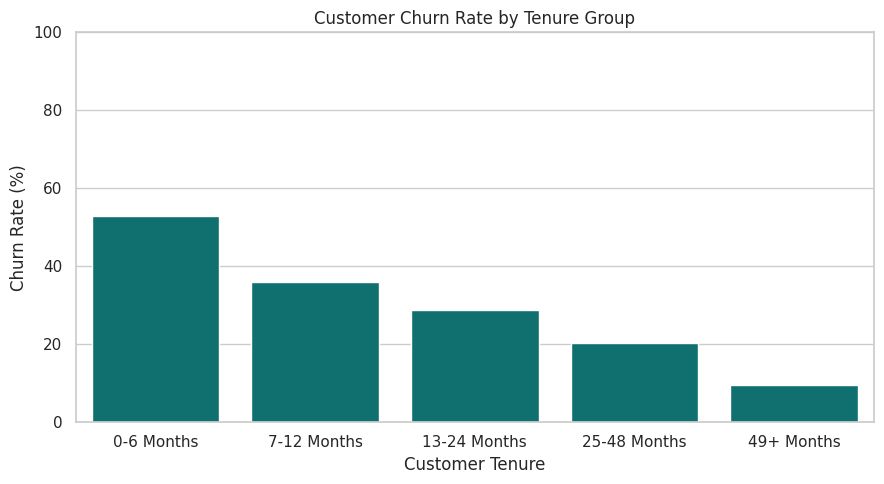

In [44]:
plt.figure(figsize=(9,5))

sns.barplot(
    data = tenure_churn,
    x = "TenureGroup",
    y = "ChurnRate",
    color = "teal"
)
plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0,100)

plt.tight_layout()
plt.savefig("churn_rate_by_tenure_group", dpi=200, bbox_inches = "tight")
plt.show()

***Monthly charges vs churn***

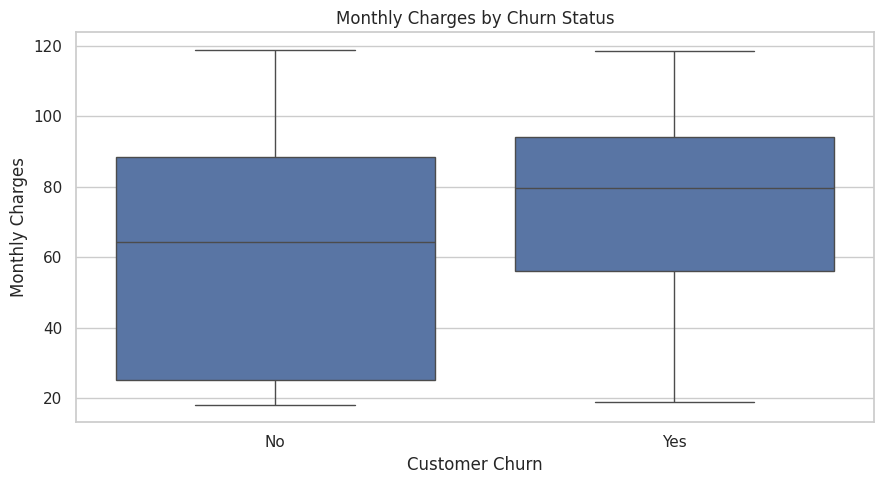

In [45]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data = eda,
    x = "Churn",
    y = "MonthlyCharges",
    order = ["No", "Yes"]
)
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.savefig("monthly_charges_by_churn_status", dpi=200, bbox_inches = "tight")
plt.show()

***Payment method vs Churn***

In [31]:
payment_churn =(
    eda.groupby("PaymentMethod")["ChurnFlag"]
    .agg(["count", "mean"])
    .reset_index()
)

payment_churn.columns = [
    "PaymentMethod",
    "TotalCustomers",
    "ChurnRate"
]

payment_churn["ChurnRate"] *= 100

print("Churn Rate by Payment Method")
display(payment_churn.round(2))

Churn Rate by Payment Method


,PaymentMethod,TotalCustomers,ChurnRate
0,Bank transfer (automatic),1544,16.71
1,Credit card (automatic),1522,15.24
2,Electronic check,2365,45.29
3,Mailed check,1612,19.11


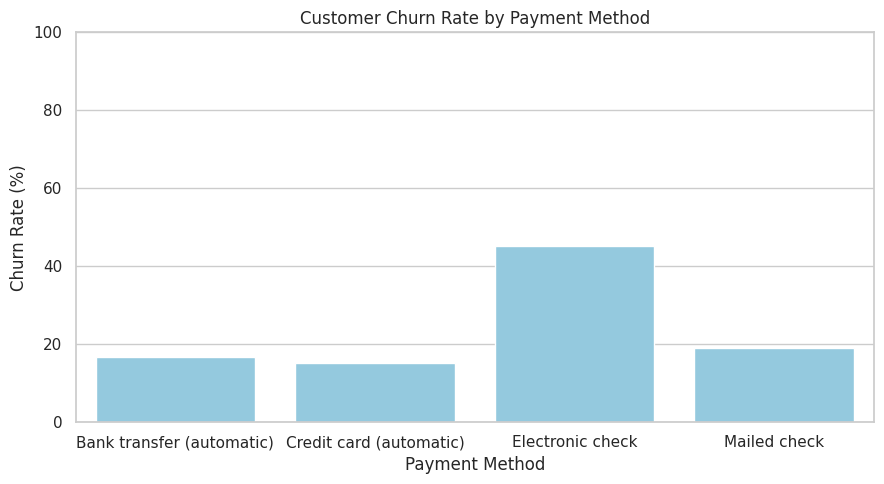

In [46]:
plt.figure(figsize=(9,5))

sns.barplot(
    data = payment_churn,
    x = "PaymentMethod",
    y = "ChurnRate",
    color = "skyblue"
)
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0,100)

plt.tight_layout()
plt.savefig("churn_rate_by_payment_method", dpi=200, bbox_inches = "tight")
plt.show()

## **Bivariate Exploratory Data Analysis**

### **Customer Churn Analysis by Contract Type**

**Observation:**

Month-to-month customers have the highest churn rate (around 42%), followed by one-year contracts (11%) and two-year contracts (3%).

**Business Interpretation:**

Customers with shorter contracts are more likely to leave. The company should encourage longer-term contracts through discounts and loyalty offers to improve customer retention.

### **Customer Churn Analysis by Tenure Group**

**Observation:**

Customers with 0–6 months of tenure have the highest churn rate (around 53%). The churn rate gradually decreases as customer tenure increases, reaching approximately 8% for customers with 49+ months.

**Business Interpretation:**

New customers are more likely to leave, while long-term customers tend to stay. The company should focus on improving customer experience and providing early loyalty offers to retain new customers.

### **Customer Churn Analysis by Monthly Charges**

**Observation:**

Customers who churn (Yes) generally have higher monthly charges, with a median of around 80 dollars, compared to approximately $65 for customers who stay (No).

**Business Interpretation:**

Higher monthly charges may be associated with customer churn. The company should focus on offering affordable plans, personalized discounts, and better value for money to improve customer retention.

### **Customer Churn Analysis by Payment Method**

**Observation:**

Customers using electronic checks have the highest churn rate (around 40%), while other payment methods have much lower churn rates (around 13–20%).

**Business Interpretation:**

Electronic check users are more likely to leave the company. The company should investigate their dissatisfaction and encourage convenient automatic payment options to improve customer retention.

# **Advanced EDA and Business Insights**

## **Multivariate Exploratory Data Analysis / Segment Analysis**

***Analyze contract type and tenure together***

In [33]:
# Analyze churn by contract and tenure together

segment_analysis = (
    eda.groupby(
        ["TenureGroup", "Contract"],
        observed = True
    )["ChurnFlag"]
    .agg(
        Customers = "size",
        Churned = "sum",
        ChurnRate = "mean"
    )
    .reset_index()
)

segment_analysis["ChurnRate"] *= 100

print("Churn Analysis by Contract and Tenure")
display(segment_analysis.round(2))

Churn Analysis by Contract and Tenure


,TenureGroup,Contract,Customers,Churned,ChurnRate
0,0-6 Months,Month-to-month,1413,780,55.20
1,0-6 Months,One year,39,4,10.26
2,0-6 Months,Two year,29,0,0.00
3,7-12 Months,Month-to-month,581,244,42.00
4,7-12 Months,One year,85,9,10.59
5,7-12 Months,Two year,39,0,0.00
6,13-24 Months,Month-to-month,737,278,37.72
7,13-24 Months,One year,197,16,8.12
8,13-24 Months,Two year,90,0,0.00
9,25-48 Months,Month-to-month,802,264,32.92


In [34]:
# Identify groups with fewer than 30 customers
small_groups = segment_analysis[
    segment_analysis.Customers < 30
]
print("Groups with fewer than 30 customers:")
display(small_groups)

Groups with fewer than 30 customers:


,TenureGroup,Contract,Customers,Churned,ChurnRate
2,0-6 Months,Two year,29,0,0.0


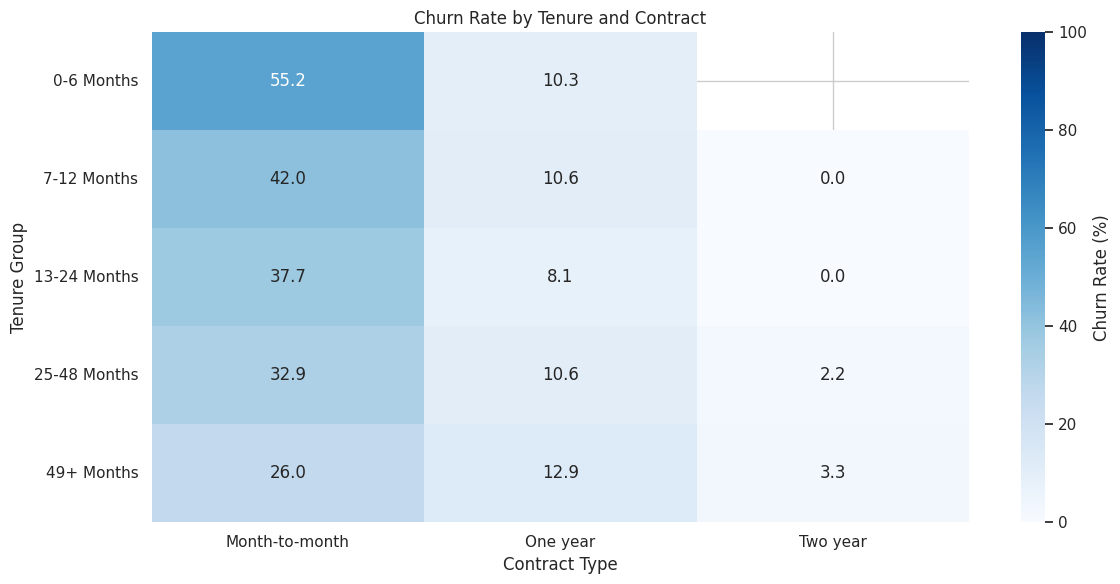

In [47]:
# Churn Rates Table
churn_heatmap = segment_analysis.pivot(
    index = "TenureGroup",
    columns = "Contract",
    values = "ChurnRate"
)

# Customer Counts Table
count_heatmap = segment_analysis.pivot(
    index = "TenureGroup",
    columns = "Contract",
    values = "Customers"
)

plt.figure(figsize=(12,6))

sns.heatmap(
    churn_heatmap,
    annot = True,
    fmt = ".1f",
    cmap = "Blues",
    vmin = 0,
    vmax = 100,
    mask = count_heatmap.lt(30),
    cbar_kws = {"label": "Churn Rate (%)"}
)
plt.title("Churn Rate by Tenure and Contract")
plt.xlabel("Contract Type")
plt.ylabel("Tenure Group")

plt.tight_layout()
plt.savefig("churn_rate_by_tenure_and_contract", dpi=200, bbox_inches = "tight")
plt.show()

***Investigate Internet Service and Churn***

In [36]:
internet_analysis = (
    eda.groupby("InternetService")["ChurnFlag"]
    .agg(
        Customers = "size",
        Churned = "sum",
        ChurnRate = "mean"
    )
    .reset_index()
)

internet_analysis["ChurnRate"] *= 100

print("Churn Analysis by Internet Service")
display(internet_analysis.round(2))

Churn Analysis by Internet Service


,InternetService,Customers,Churned,ChurnRate
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No,1526,113,7.40


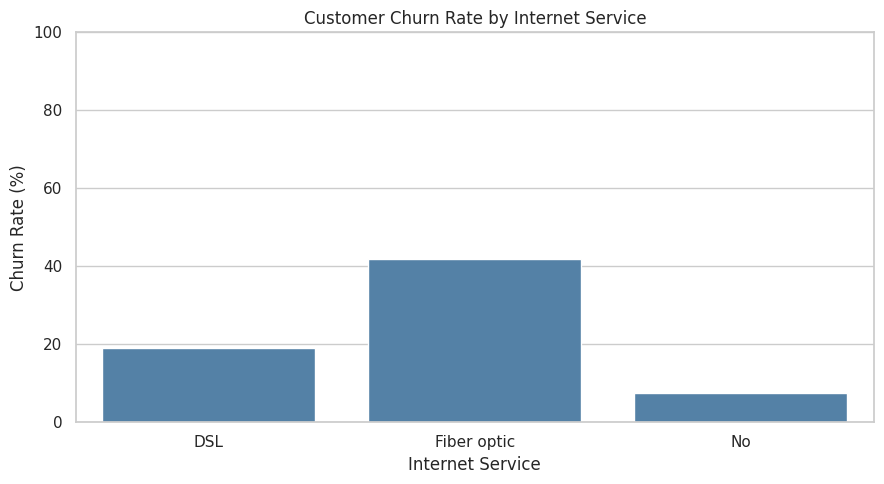

In [48]:
plt.figure(figsize=(9,5))

sns.barplot(
    data = internet_analysis,
    x = "InternetService",
    y = "ChurnRate",
    color = "steelblue"
)
plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0,100)

plt.tight_layout()
plt.savefig("churn_rate_by_internet_service", dpi=200, bbox_inches = "tight")
plt.show()

# **Validate Results**

In [38]:
# Check the number of customers
assert len(eda) == 7043

# Check the number of churned customer
assert eda.ChurnFlag.sum() == 1869

# Check all internet-service groups
assert internet_analysis.Customers.sum() == len(eda)

# Check overall churn rate
overall_churn = eda.ChurnFlag.mean() * 100

# Recalculate from the internet-service groups
group_churn = (
    internet_analysis.Churned.sum()
    / internet_analysis.Customers.sum()
) * 100

# Compare the two results
assert np.isclose(overall_churn, group_churn)

print("All validation checks passed!")
print("Total customers:", len(eda))
print("Churned customers:", eda.ChurnFlag.sum())
print("Remaining missing values:", df_clean.isna().sum().sum())
print("Duplicate records:", df_clean.duplicated().sum())
print(f"Overall churn rate: {overall_churn:.2f}%")


All validation checks passed!
Total customers: 7043
Churned customers: 1869
Remaining missing values: 0
Duplicate records: 0
Overall churn rate: 26.54%


## **Advanced EDA: Customer Segmentation and Business Insights**

### **Contract Type and Customer Tenure**

**Observation:**

Customers with 0–6 months of tenure on month-to-month contracts have the highest churn rate (55.2%). Churn generally decreases with longer tenure among month-to-month customers. Two-year contracts show the lowest observed churn rates (0–3.3%).

**Business Interpretation:**

New customers with month-to-month contracts are the most vulnerable to churn. Longer contracts are associated with better customer retention, even across different tenure groups.

**Recommendation:**

The company should focus on early customer engagement, personalized retention offers, and incentives for longer-term contracts to reduce churn among high-risk customers.


### **Internet Service and Customer Churn**

**Observation:**

Fiber optic customers have the highest churn rate (around 42%), followed by DSL customers (19%). Customers without internet service have the lowest churn rate (around 8%).

**Business Interpretation:**

Fiber optic customers are more likely to leave the company. This may indicate issues related to pricing, service quality, or customer satisfaction that require further investigation.

**Recommendation:**

Investigate service experience and customer characteristics within higher-churn groups.

## **Business Conclusion and Recommendations**

### **Key Findings:**

The exploratory analysis of 7,043 telecommunications customer records identified several notable patterns associated with customer churn. Overall, 1,869 customers (26.54%) were classified as churned.

**The key findings include:**

- **Contract Type:** Month-to-month customers had the highest observed churn rate (approximately 42%), compared with substantially lower rates among one-year and two-year contract customers.

- **Customer Tenure:** Customers with shorter tenure showed higher churn rates. Within the month-to-month category, customers with 0–6 months of tenure had an observed churn rate of 55.2%, compared with 26.0% among customers with 49 or more months.

- **Monthly Charges:** Churned customers had higher median monthly charges (approximately 80 dollars) than retained customers (approximately $65).

- **Internet Service:** Fiber-optic customers showed the highest observed churn rate (approximately 42%), compared with DSL customers (approximately 19%) and customers without internet service (approximately 8%).

- **Payment Method:** Electronic-check customers showed higher observed churn (approximately 40%) than customers using other payment methods.

### **Business Interpretation:**

The findings suggest that contract flexibility, customer tenure, service categories, payment methods, and monthly charges are useful characteristics for investigating customer retention.
Newer customers with month-to-month contracts appear to be an important group for further retention analysis. Higher churn within certain service and payment categories may also reflect differences in customer characteristics, pricing, or service experience.
However, these exploratory findings demonstrate associations rather than direct causal relationships. Further investigation is needed to understand the underlying reasons for customer cancellation.

### **Business Recommendations:**

Based on these findings, the company should consider the following actions:

- **Improve early customer engagement:** Investigate onboarding experiences and support needs among customers with shorter tenure.

- **Evaluate contract incentives:** Test whether suitable loyalty benefits or longer-term subscription offers improve retention.

- **Investigate fiber-optic customer experience:** Examine service quality, pricing, support records, and customer feedback within this group.

-  **Review payment experiences:** Investigate whether payment convenience, billing concerns, or other characteristics are associated with the elevated churn among electronic-check users.

- **Test targeted retention programs:** Conduct controlled pilot interventions for selected customer groups and evaluate their effectiveness before wider implementation.


### **Data Quality, Validation and Limitations**
The dataset contained 11 initially blank TotalCharges values, all associated with customers whose tenure was zero months. These values were replaced with zero for the exploratory analysis under a documented assumption.

The cleaned dataset contains 7,043 customer records, with no remaining missing values or exact duplicate rows. All implemented validation checks passed, confirming consistency between the overall customer and churn totals and the corresponding segmented analyses. The observed churn proportion was 26.54%.

The dataset is a sample of customer records, and the observation period for the churn outcome is not established in this analysis. Therefore, the reported churn proportion should not be interpreted as a monthly or annual churn rate.

Additionally, some customer segments contain relatively few records, and multiple customer characteristics may overlap. The analysis does not establish whether pricing, service quality, payment method, or contract type independently causes churn.

### **Final Conclusion:**

The exploratory analysis identifies several customer groups that may deserve closer attention in a retention strategy, particularly newer customers with month-to-month contracts.
Rather than applying the same retention measures to all customers, the company could use these findings to prioritize further investigation and design targeted interventions.
By validating the underlying reasons for customer cancellation and testing suitable retention strategies, the company may be able to improve customer experience and reduce customer loss. The effectiveness of such interventions must be evaluated using additional evidence.